In [ ]:
outpath= '/content/drive/MyDrive/John/Work/Research/01_In_Progress/ResearchMaterial/Deep Learning/code/'

In [ ]:
# --- Celda 1: imports + datos ---
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
tf = transforms.ToTensor()
train_ds = datasets.MNIST('./data', train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST('./data', train=False, download=True, transform=tf)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

In [ ]:
# --- Celda 2: Fórmula de salida de conv y pooling ---
def conv_out(size, kernel, padding=0, stride=1):
    return (size + 2*padding - kernel)//stride + 1

print("Padding / stride / kernel  ->  tamaño de salida sobre entrada 28x28")
for k, p, s in [(3,0,1), (3,1,1), (3,1,2), (5,2,1), (5,2,3)]:
    print(f"  K={k}, P={p}, S={s} -> {conv_out(28,k,p,s)}")

Padding / stride / kernel  ->  tamaño de salida sobre entrada 28x28
  K=3, P=0, S=1 -> 26
  K=3, P=1, S=1 -> 28
  K=3, P=1, S=2 -> 14
  K=5, P=2, S=1 -> 28
  K=5, P=2, S=3 -> 10


In [ ]:
# --- Celda 3: CNN pequeña ---
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # (1,28,28) -> (16,28,28)
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            # pooling -> (16,14,14)
            nn.MaxPool2d(2),
            # (16,14,14) -> (32,14,14)
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            # pooling -> (32,7,7)
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32*7*7, 64), nn.ReLU(),
            nn.Linear(64, num_classes),
        )
    def forward(self, x): return self.classifier(self.features(x))

cnn = SmallCNN().to(device)
print(f"Parámetros CNN: {sum(p.numel() for p in cnn.parameters()):,}")
print("(compárese con ~200k del MLP del notebook anterior)")

Parámetros CNN: 105,866
(compárese con ~200k del MLP del notebook anterior)


In [ ]:
# --- Celda 4: entrenamiento ---
def train_cls(model, loader, epochs=5, lr=1e-3):
    crit = nn.CrossEntropyLoss()
    opt  = optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train(); correct = total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = crit(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
        print(f"ep {ep+1} | train acc = {correct/total:.4f}")

train_cls(cnn, train_loader, epochs=5)

def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct/total
print(f"Test acc CNN: {evaluate(cnn, test_loader):.4f}")

torch.save(cnn.state_dict(), f'{outpath}/cnn_mnist.pt')

ep 1 | train acc = 0.8959
ep 2 | train acc = 0.9734
ep 3 | train acc = 0.9807
ep 4 | train acc = 0.9845
ep 5 | train acc = 0.9866
Test acc CNN: 0.9857


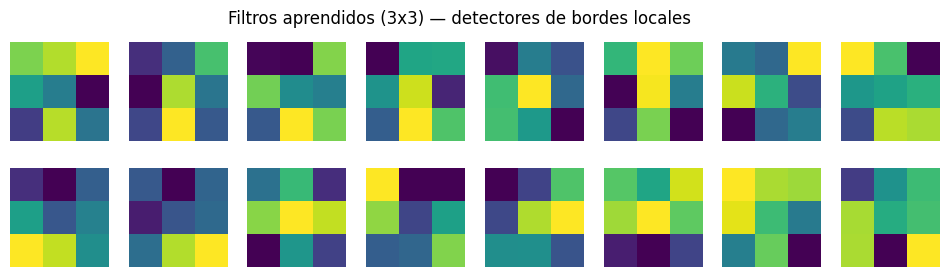

In [ ]:
# --- Celda 5: visualizar kernels aprendidos de la 1ª capa ---
w = cnn.features[0].weight.detach().cpu()   # (16, 1, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i, 0], cmap='viridis'); ax.axis('off')
plt.suptitle("Filtros aprendidos (3x3) — detectores de bordes locales")
plt.show()

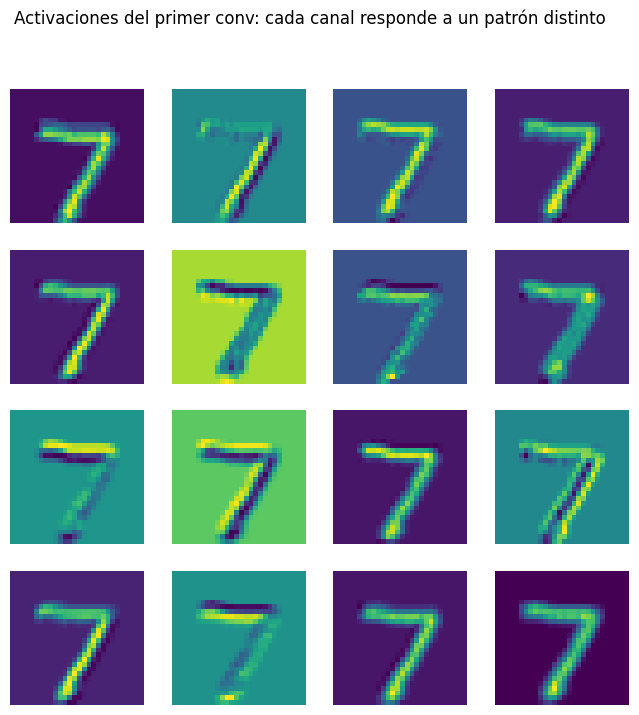

In [ ]:
# --- Celda 6: mapas de activación (16 canales) ---
x0 = test_ds[0][0].unsqueeze(0).to(device)
with torch.no_grad():
    acts = cnn.features[0](x0)       # (1, 16, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(acts[0, i].cpu(), cmap='viridis'); ax.axis('off')
plt.suptitle("Activaciones del primer conv: cada canal responde a un patrón distinto")
plt.show()

In [ ]:
# --- Celda 7: CNN es robusta a traslaciones ---
mlp = SmallCNN()  # placeholder
mlp_state = torch.load(f'{outpath}/mlp_mnist.pt', map_location=device)

# comparamos CNN (ya entrenada) vs MLP (cargado) sobre la misma imagen trasladada
from torch import nn as _nn
class MLPClassifier(_nn.Module):
    def __init__(self, hidden=256):
        super().__init__()
        self.net = _nn.Sequential(
            _nn.Flatten(),
            _nn.Linear(784, hidden), _nn.ReLU(),
            _nn.Linear(hidden, hidden), _nn.ReLU(),
            _nn.Linear(hidden, 10))
    def forward(self, x): return self.net(x)

mlp = MLPClassifier().to(device); mlp.load_state_dict(mlp_state); mlp.eval()

x0, y0 = test_ds[4]
x0 = x0.unsqueeze(0).to(device)
shift = torch.roll(x0, shifts=6, dims=3)
with torch.no_grad():
    print(f"MLP  original: {mlp(x0).argmax().item():>2d}   trasladada: {mlp(shift).argmax().item():>2d}")
    print(f"CNN  original: {cnn(x0).argmax().item():>2d}   trasladada: {cnn(shift).argmax().item():>2d}")
print(f"Etiqueta real: {y0}")

MLP  original:  4   trasladada:  2
CNN  original:  4   trasladada:  4
Etiqueta real: 4
